# Transactions across market boundaries (joint seams workshop, September 16, 2026)

This notebook reproduces the four examples of transactions between two market engines on the WSCC 9-bus network, slide by slide. The slide checks are in `tests/test_slides_workshop3.py` and run with `python -m pytest tests -q -m slides`.

The source is the deck *Transactions across market boundaries*, presented at the CAISO and SPP joint market seams workshop of September 16, 2026 (`caiso_spp_workshop_sep2026`). SPP posts the deck in the workshop's slide-deck archive at [https://spp.org/documents/77788/joint%20market%20seams%20workshop%20slide%20decks%2020270916.zip](https://spp.org/documents/77788/joint%20market%20seams%20workshop%20slide%20decks%2020270916.zip). The notebook numbers the slides 1 to 34 from the deck's own title slide, so slide 1 is the title and slide 2 lists the four examples. The posted file carries the workshop's panel title slide in front, so its slide $n+1$ is this notebook's slide $n$.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pdockery/wscc9-illustrative-model/blob/main/workshop3_transactions_across_boundaries.ipynb)

In [1]:
#@title ▶ Run me first: Colab setup (installs packages, fetches the library)
# On Google Colab this installs the packages Colab lacks and downloads the
# library modules into lib/. Run locally, it walks up from the working
# directory to the folder that holds lib/seams_engine.py.
import pathlib
import subprocess
import sys

LIB_MODULES = (
    "seams_engine", "wscc9_model", "ieee9_network", "nodal_plot",
    "wscc9_figures", "seam_views", "etag", "risk", "revenue_allocation",
    "atc", "bilateral", "footprints", "intertie", "lab_types",
)


def _sh(cmd: str) -> None:
    print("$", cmd)
    subprocess.run(cmd, shell=True, check=True)


if "google.colab" in sys.modules:
    _sh("pip install -q pypsa pandapower pycirclize")
    _base = "https://raw.githubusercontent.com/pdockery/wscc9-illustrative-model/main/lib"
    _lib = pathlib.Path("lib").resolve()
    _lib.mkdir(exist_ok=True)
    for _m in LIB_MODULES:
        _sh(f"wget -q {_base}/{_m}.py -O {_lib / (_m + '.py')}")
    print("Colab setup complete.")
else:
    _r = pathlib.Path.cwd().resolve()
    while not (_r / "lib" / "seams_engine.py").exists() and _r != _r.parent:
        _r = _r.parent
    _lib = _r / "lib"
    print("Local run: modules from the repository's lib/")
if str(_lib) not in sys.path:
    sys.path.insert(0, str(_lib))

Local run: modules from the repository's lib/


In [2]:
import logging
import warnings
from typing import Any

import matplotlib.pyplot as plt
import pandas as pd
import pypsa
from IPython.display import display
from matplotlib.figure import Figure
from matplotlib.patches import Patch

import footprints as fpmod
import seam_views as sv
import wscc9_figures as figs
import wscc9_model as wm
from footprints import Footprints
from nodal_plot import plot_combined_letter, plot_network_topology
from seams_engine import (
    EngineResult,
    MarketEngine,
    PTDFData,
    compute_ptdf,
    solve_engine_dispatch,
    solve_engine_qp,
    susceptance_widths,
)
from wscc9_model import BUS_COLORS, CENTER_BUS, COORDS, RING_ORDER, build_network, make_engine

warnings.filterwarnings("ignore")
for _name in ("pypsa", "ieee9_network"):
    logging.getLogger(_name).setLevel(logging.ERROR)
pd.set_option("display.width", 160)
# Inline frames draw no suptitle, panel title or legend, and no file is written.
sv.configure(strip_inline=True, save_enabled=False)

## Formulation

Two market engines share one network. Each engine clears its own resources against its own load, enforces only the lines it activates, and prices every bus of the shared network from its own offers. The nomenclature table maps each symbol to its object in the library or in this notebook.

| Symbol | Code | Definition |
|---|---|---|
| $\mathcal N$, $n$ / $\mathcal M$, $m$ | `PT.buses`, `PT.lines` | the bus set and the network line set of the shared network |
| $\mathcal E$, $M$ | `MKT_DEFS` | the set of market engines on the shared network, and one engine |
| $\mathcal N^M$, $\mathcal R^M$ | `MKT_DEFS[M]`, `engine(M).gens` | the buses market $M$ serves, its footprint, and the resources it dispatches |
| $\mathcal M^M_{\mathrm{mon}}$ | `MONITORED_LINES[M]` | the lines market $M$ models and watches |
| $\mathcal M^M_{\mathrm{act}}$ | `ACTIVATED_LINES[M]` | the lines whose limits enter market $M$'s clearing |
| $c_i$, $\bar g_i$, $g_i$, $\mathrm{bus}(i)$ | `FLEET`, `res.dispatch` | resource $i$'s offer, capacity, dispatch and host bus |
| $MC_i$, $a_i$, $b_i$ | `CURVES_TX` | resource $i$'s marginal cost, and the intercept and slope of its rising offer curve |
| $d_n$ | `LOADS` | the load at bus $n$, served by the market whose footprint holds $n$ |
| $g^M_n$, $d^M_n$ | `res.dispatch`, `LOADS` | market $M$'s generation at bus $n$, and the load it serves there, both zero outside its footprint |
| $\mathrm{exo}^M_n$ | `exo=` | the fixed exogenous injection market $M$ carries at bus $n$, positive into the network |
| $p^{\mathrm{inj},M}_n$ | `res.injection` | market $M$'s net injection at bus $n$ |
| $SF_{n,m}$ | `PT.ptdf[PT.line_idx[m], PT.bus_idx[n]]` | the shift factor of bus $n$ on line $m$, bus first in the symbol and line first in the array |
| $F^M_m$, $\bar F_m$ | `res.flow_own`, `PT.s_nom` | market $M$'s own flow on line $m$, and the line's rating |
| $\lambda^M$, $\lambda^M_n$ | `res.energy_price`, `res.lmp` | market $M$'s energy price, and its nodal price at bus $n$ |
| $\mu^M_m$ | `res.line_dual` | market $M$'s signed dual on line $m$ |
| $R^M$ | `R_A1`, `R_CANON` | market $M$'s congestion rent |
| $\Delta g^M_{i,n}$ | `sv.price_walk` | the redispatch of resource $i$ when market $M$ serves one more MW at bus $n$ |
| $s$, $k$ | `SOURCE_BUS`, `SINK_BUS`, `TX_BID` | a transaction's source bus and sink bus, in different footprints |
| $M_s$, $M_k$ | `tx_legs` | the source market, whose footprint holds $s$, and the sink market, whose footprint holds $k$ |
| $S$ | `S_SCHED` | the self-schedule's quantity, MW |
| $P$, $Q$ | `BID_3`, `QTY_3`, `BID_4`, `QTY_4` | a bid's price, \$/MWh, and quantity, MW |
| $S_M$, $S^{\mathrm{tag}}$ | `award`, `st["tagged"]` | market $M$'s award on a bid, and the lesser award, MW |
| $S'$ | `mw` in `price_at` | a trial volume carried at the node during the bisection of an award, MW |
| $\lambda^{M,\mathrm{rt}}_n$, $\lambda^{\mathrm{rt}}$ | `st["rt"]["price"]` | market $M$'s real-time price at bus $n$, and the real-time price at which the open position settles |
| $\Pi$ | `st["pi"]` | the scheduler's net settlement across both markets, \$/h |

Lower-case $m$ indexes a line, upper-case $M$ names a market engine, and script $\mathcal M$ is the network line set.

**The clearing.** Market $M$ minimizes the offered cost of its own resources, subject to its own power balance and the limits on the lines it activates.

$$\begin{aligned}
\min_{0\le g_i\le\bar g_i}\ \ &\sum_{i\in\mathcal R^M}c_i\,g_i\\
\text{s.t.}\ \ &\sum_{i\in\mathcal R^M}g_i-\sum_{n\in\mathcal N^M}d_n+\sum_{n\in\mathcal N}\mathrm{exo}^M_n=0 && [\lambda^M]\\
&-\bar F_m\le F^M_m\le\bar F_m,\quad m\in\mathcal M^M_{\mathrm{act}} && [\mu^M_m]
\end{aligned}\qquad(1)$$

*In words.* Market $M$ minimizes the offered cost $\sum_i c_i\,g_i$ of the resources $\mathcal R^M$ it dispatches, choosing each dispatch $g_i$ within its capacity $\bar g_i$, subject to two constraint families: one power balance, in which market $M$'s generation less the load $d_n$ it serves in its footprint $\mathcal N^M$ plus every fixed exogenous injection $\mathrm{exo}^M_n$ sums to zero (dual $\lambda^M$, market $M$'s energy price); and its own flow $F^M_m$ held within the rating $\bar F_m$ on each activated line $m\in\mathcal M^M_{\mathrm{act}}$ (dual $\mu^M_m$, that line's signed shadow price).

A shed variable priced at `SHED_PRICE` relaxes the balance, and no clearing in this notebook sheds.

$$F^M_m=\sum_{n\in\mathcal N}SF_{n,m}\,p^{\mathrm{inj},M}_n,\qquad p^{\mathrm{inj},M}_n=g^M_n-d^M_n+\mathrm{exo}^M_n,\qquad m\in\mathcal M.\qquad(2)$$

*In words.* Market $M$'s own flow on line $m$, $F^M_m$, is the shift factor $SF_{n,m}$ of each bus on that line times the market's net injection $p^{\mathrm{inj},M}_n$ there, summed over every bus $n\in\mathcal N$. The net injection is market $M$'s generation $g^M_n$ at bus $n$, less the load $d^M_n$ it serves there, plus its fixed exogenous injection $\mathrm{exo}^M_n$. The generation and the load are zero outside its footprint.

Note that $F^M_m$ counts market $M$'s own injections only. Each network panel in this notebook labels a line with that market's own flow against the rating. Market A enforces only its own flow on line 6-7, and Market B does not activate that line, so neither market prices the flow the two dispatches place on it together.

$$\lambda^M_n=\lambda^M+\sum_{m\in\mathcal M^M_{\mathrm{act}}}SF_{n,m}\,\mu^M_m,\qquad n\in\mathcal N.\qquad(3)$$

*In words.* Market $M$'s nodal price $\lambda^M_n$ at bus $n$ is its energy price $\lambda^M$ plus, for each line $m$ it activates, the shift factor $SF_{n,m}$ of bus $n$ on that line times the line's signed dual $\mu^M_m$. The index $n$ runs over the whole network $\mathcal N$, so the identity prices a bus that market $M$ does not serve.

The EDAM technical description derives its prices the same way: "The marginal prices for the various commodities in EDAM are derived from the shadow prices of binding constraints" (`caiso_edam_techdesc`, p. 25). Its price formula writes the dual with a minus sign, so its $\mu_{m,t}$ is the negative of the signed $\mu^M_m$ of (3). The formula also divides the energy price by each node's loss penalty factor (`caiso_edam_techdesc`, p. 26). This notebook is lossless, and every loss penalty factor is 1. Each market prices every bus of the network from its own constraints. The coordination protocol of `cadwalader1999coordinating` splits monitoring the same way (p. 23): "Each regional system operator need monitor only its own constraints, but it does need to determine the flows in the network." The protocol exchanges prices between the operators: "Given the prices, each system operator needs to keep track only of its own constraints" (`cadwalader1999coordinating`, p. 21). This notebook keeps the protocol's split of monitoring, in which each market enforces only its own constraints. It holds each constraint against the market's own flow component $F^M_m$. The markets exchange no prices. Neither market therefore prices the superposition of the two dispatches.

$$R^M=\sum_{m\in\mathcal M^M_{\mathrm{act}}}\lvert\mu^M_m\rvert\,\lvert F^M_m\rvert.\qquad(4)$$

*In words.* Market $M$'s congestion rent $R^M$ is the absolute dual $\lvert\mu^M_m\rvert$ times the absolute own flow $\lvert F^M_m\rvert$, summed over the lines it activates.

The anchor is the canonical clearing of the 9-bus case, one engine over all nine buses with line 6-7 rated 40 MW. It binds that line at a signed dual $\mu_m$ of −\$20.10/MWh with a congestion rent $R=\$804.1$/h. Market A's own clearing in Example 1 reproduces it, binding the same line at the same dual with the same rent.

**The redispatch behind a price.** Serving one more MW of load at bus $n$ moves market $M$'s marginal resources while every binding line stays at its limit:

$$\sum_i\Delta g^M_{i,n}=1,\qquad\sum_i SF_{\mathrm{bus}(i),m}\,\Delta g^M_{i,n}=SF_{n,m}\quad\text{for each binding }m\in\mathcal M^M_{\mathrm{act}}.\qquad(5)$$

*In words.* The redispatch $\Delta g^M_{i,n}$ of market $M$'s marginal resources sums to the one MW delivered, and on each binding line $m$ the flow it places, each resource's redispatch times the shift factor $SF_{\mathrm{bus}(i),m}$ of its host bus, equals the flow $SF_{n,m}$ that the MW at bus $n$ adds.

$$\lambda^M_n=\sum_i c_i\,\Delta g^M_{i,n}.\qquad(6)$$

*In words.* Market $M$'s price $\lambda^M_n$ at bus $n$ is each marginal resource's offer $c_i$ times its redispatch $\Delta g^M_{i,n}$, summed. Note that (5) and (6) read only market $M$'s own offers and the shared shift factors, so they price a bus outside its footprint by the same arithmetic as a bus inside it.

Solving (5) with right-hand sides $-1$ and $-SF_{n,m}$ describes one more MW of generation at bus $n$. Every $\Delta g^M_{i,n}$ reverses sign and (6) sums to $-\lambda^M_n$, so $\lambda^M_n$ is also the production cost market $M$ avoids when one MW is delivered at bus $n$, the marginal value of generation there. Slides 7 and 11 read a price as the cost of serving load, and slide 9 reads one as the value of generation.

**A self-schedule across the seam.** A transaction runs from a source bus $s$ to a sink bus $k$ in different footprints. The source market $M_s$ holds $s$, and the sink market $M_k$ holds $k$. A price-taking self-schedule of $S$ MW is fixed before either market clears, and each market carries as a fixed injection the end that lies outside its footprint:

$$\mathrm{exo}^{M_k}_s=+S,\qquad\mathrm{exo}^{M_s}_k=-S.\qquad(7)$$

*In words.* The sink market $M_k$ carries the schedule as an injection of $S$ MW at the source bus $s$, and its own load at $k$ absorbs the delivery. The source market $M_s$ carries it as a withdrawal of $S$ MW at the sink bus $k$, and its own resources at $s$ supply it.

Equation (7) places each leg at the transaction's named source or sink bus, as the deck does. CAISO models an intertie schedule in one of two other ways (`caiso_intertie_modeling2026`, slide 7). SP-Tie modeling, in place on the interties of the CAISO balancing authority area, places it at the scheduling point: "Intertie transactions at scheduling points are modeled as injection (import) or ejection (export) of energy directly at the intertie location". GAP-Tie modeling sources a schedule from aggregate generation in the neighbouring area. It is in place on the interties of WEIM balancing authority areas and will take effect on those of non-CAISO EDAM balancing authority areas. Fixing $S$ before the clearing, with no bid price, is also this notebook's modeling choice.

$$\Pi=\lambda^{M_k}_s\,S-\lambda^{M_s}_k\,S.\qquad(8)$$

*In words.* The scheduler's net settlement $\Pi$ is what the sink market pays for the injection at the source bus, its price $\lambda^{M_k}_s$ times the scheduled quantity $S$, less what the source market charges for the withdrawal at the sink bus, its price $\lambda^{M_s}_k$ times $S$.

**A price-sensitive bid.** A bid carries a price $P$ and a quantity $Q$. Each market enters it in (1) at the node of (7), as an offer at $P$ in the sink market and as a bid at $P$ in the source market. The sink market buys an injection at $s$, and the source market sells a withdrawal at $k$. A market's price at its node is monotone in the volume it carries there, so the award the clearing makes is the largest volume at which that price stays on the accepting side of the bid:

$$S_{M_k}=\max\{S'\le Q:\ \lambda^{M_k}_s(S')\ge P\},\qquad S_{M_s}=\max\{S'\le Q:\ \lambda^{M_s}_k(S')\le P\}.\qquad(9)$$

*In words.* The sink market's award $S_{M_k}$ is the largest volume $S'$ within the bid quantity $Q$ at which its price at the source bus, $\lambda^{M_k}_s(S')$ with $S'$ carried there as in (7), is at or above the bid price $P$. The source market's award $S_{M_s}$ is the largest volume at which its price at the sink bus, $\lambda^{M_s}_k(S')$, is at or below $P$.

A bid accepted in part, with an award $S_M$ above zero and below $Q$, is the marginal bid or offer of market $M$'s clearing, so market $M$'s price at its node is $P$. The bisection in the helpers cell finds the award of (9), and the settlement prices a partial award at $P$.

Note that each market reads the bid against its own price only. Under the flat offers of Example 3 neither price moves over the bid quantity, so each award is $Q$ or nothing.

$$\Pi=\lambda^{M_k}_s\,S_{M_k}-\lambda^{M_s}_k\,S_{M_s}.\qquad(10)$$

*In words.* The scheduler's day-ahead settlement $\Pi$ is the sink market's price at the source bus times its award $S_{M_k}$, less the source market's price at the sink bus times its award $S_{M_s}$.

**Rising offer curves.** Example 4 replaces each flat offer with a marginal cost that rises with output:

$$MC_i(g_i)=a_i+b_i\,g_i,\qquad\text{offered cost }a_i\,g_i+\tfrac12\,b_i\,g_i^2.\qquad(11)$$

*In words.* Resource $i$'s marginal cost $MC_i$ at output $g_i$ is its intercept $a_i$ plus its slope $b_i$ times $g_i$, and its offered cost, which replaces $c_i\,g_i$ in (1), is the area under that line. The flat offer is the case $b_i=0$, $a_i=c_i$.

Note that under (11) a market's price at its node moves with the volume it carries. The selling market's price rises and the buying market's price falls. The two awards of (9) can therefore differ.

**The open position and its real-time settlement.** Only the lesser award can be tagged. The tagged volume $S^{\mathrm{tag}}$ is the lesser of the two awards $S_{M_k}$ and $S_{M_s}$. The scheduler holds the open position $S_{M_k}-S_{M_s}$ in the market with the larger award, which re-clears in real time with $S^{\mathrm{tag}}$ at its node:

$$\Pi=\lambda^{M_k}_s\,S_{M_k}-\lambda^{M_s}_k\,S_{M_s}-\big(S_{M_k}-S_{M_s}\big)\,\lambda^{\mathrm{rt}},\qquad\lambda^{\mathrm{rt}}=\begin{cases}\lambda^{M_k,\mathrm{rt}}_s & S_{M_k}>S_{M_s}\\[2pt]\lambda^{M_s,\mathrm{rt}}_k & S_{M_k}<S_{M_s}.\end{cases}\qquad(12)$$

*In words.* The scheduler's net settlement $\Pi$ is its day-ahead settlement (10) less the open position $S_{M_k}-S_{M_s}$ times the real-time price $\lambda^{\mathrm{rt}}$. Where the sink market awarded more, $\lambda^{\mathrm{rt}}$ is the sink market's real-time price at the source bus, at which the scheduler buys the shortfall back. Where the source market awarded more, it is the source market's real-time price at the sink bus, at which the scheduler sells the surplus back.

The real-time clearing is (1) for the same engine and the same offers, re-run with $S^{\mathrm{tag}}$ at the node, and the open position settles at that node's real-time price, not at the cost of the unit that replaces the volume. Both are this notebook's modeling choices.

## Configuration

**Edit below:** the footprints, the monitored and activated lines, the bus 1 unit's capacity, the line ratings, the loads, the price-walk buses, and each example's transaction, quantity, bid and offer curves. The values are the deck's, except the shed price `SHED_PRICE` and the offer-curve coefficients `CURVES_TX`, which the deck does not print.

In [3]:
# -- EDIT -- the case, the footprints and the four examples --------------------
MKT_DEFS = {  # footprints: the buses each market serves
    "Market A": ["2", "8", "7", "6", "3"],  # the $35 unit at bus 2, the $20 unit at bus 3
    "Market B": ["1", "9", "4", "5"],  # the $50 unit at bus 1
}
MARKET_COLORS = {"Market A": "#993AFF", "Market B": "#2471A3"}  # slide 3's palette
MONITORED_LINES = {  # M^M_mon: the lines each market models and watches
    "Market A": ["line_2", "line_3", "line_4", "line_5", "line_6"],
    "Market B": ["line_0", "line_1", "line_7", "line_8"],
}
ACTIVATED_LINES = {  # M^M_act: the monitored lines whose limits enter the clearing
    "Market A": ["line_2", "line_3", "line_4", "line_5", "line_6"],
    "Market B": ["line_0", "line_1", "line_7", "line_8"],
}
P_NOM_B1 = 300.0  # MW, the bus 1 unit's capacity (stock 250)
LINE0_RATING = 300.0  # MW, line 1-4, the bus 1 unit's outlet, raised with it
LINE4_RATING = 40.0  # MW, line 6-7, the constrained element inside Market A
LOADS = {"7": 90.0, "9": 173.0, "5": 90.0}  # MW, the loads every clearing serves
SHED_PRICE = 150.0  # $/MWh, the load-shed relaxation of (1)
# The price walks of (5) and (6): each bus in the direction the transaction uses it.
WALK_A = {"inside": "7", "outside": "1"}  # Market A's walks, slides 7 and 9
WALK_B = {"outside": "7"}  # Market B's walk, slide 11
WALK_DIRECTION = {"1": "injection", "7": "withdrawal"}
# Example 2: the price-taking self-schedule of (7) and (8).
SOURCE_BUS = "1"  # a Market B unit bus
SINK_BUS = "7"  # a Market A load bus
S_SCHED = 25.0  # MW, fixed before either market clears
# Examples 3 and 4: the price-sensitive bid of (9), on one transaction.
TX_BID = {"source": "3", "sink": "5"}  # a Market A unit bus to a Market B load bus
BID_3, QTY_3 = 40.0, 30.0  # $/MWh and MW, Example 3, flat offers
BID_4, QTY_4 = 40.0, 120.0  # $/MWh and MW, Example 4, rising curves
CURVES_TX = {  # (11): MC_i(g) = a + b g, (a in $/MWh, b in $/MWh per MW)
    "gen_slack_0": (24.0, 0.100),  # bus 1, Market B
    "gen_0": (28.0, 0.270),  # bus 2, Market A
    "gen_1": (15.0, 0.335),  # bus 3, Market A
}

The notebook-local helpers in the next cell build the case, clear one market and construct the transaction legs. They bisect the award of (9) and settle (8), (10) and (12). The clearings, the shift factors, the price walk of (5) and (6) and the seam frames come from the library in `lib/`.

In [4]:
Fleet = dict[str, dict[str, Any]]
Leg = dict[str, Any]


def build_case() -> tuple[Fleet, pypsa.Network, PTDFData, Footprints]:
    """The fleet, network, shift factors and footprints the EDIT cell sets.

    The bus 1 unit's capacity is ``P_NOM_B1`` and its outlet, line 1-4, is rated
    ``LINE0_RATING``; line 6-7 is rated ``LINE4_RATING``. The seam frames are
    configured with the footprints and the fleet, write no file, and draw no
    suptitle, panel title or legend.
    """
    fleet = {g: dict(spec) for g, spec in wm.DEFAULT_GEN_FLEET.items()}
    fleet["gen_slack_0"]["p_nom"] = float(P_NOM_B1)
    ratings = {"line_4": float(LINE4_RATING), "line_0": float(LINE0_RATING)}
    net = build_network(ratings)
    pt = compute_ptdf(net, slack_bus="1")
    fp = fpmod.make(pt, MKT_DEFS, MARKET_COLORS, monitored=MONITORED_LINES,
                    tie_label="intertie")
    sv.configure(fp=fp, gen_fleet=fleet, loads=dict(LOADS), save_enabled=False,
                 strip_inline=True)
    return fleet, net, pt, fp


def engine(mkt: str) -> MarketEngine:
    """Market ``mkt``'s engine: its footprint's units and loads, its activated lines."""
    return make_engine(mkt, MKT_DEFS[mkt], gen_fleet=FLEET, loads=LOADS,
                       activated=ACTIVATED_LINES[mkt])


def clear(mkt: str, exo: dict[str, float] | None = None,
          curves: dict[str, tuple[float, float]] | None = None,
          ) -> tuple[MarketEngine, EngineResult]:
    """Equation (1) for market ``mkt``, with fixed injections ``exo`` in MW.

    ``exo`` maps a bus to MW, positive into the network. With ``curves``, a map of
    unit to ``(a, b)``, the offers are the rising curves of (11).
    """
    eng = engine(mkt)
    if curves:
        res = solve_engine_qp(PT, eng, curves=curves, exo=exo, shed_price=SHED_PRICE)
    else:
        res = solve_engine_dispatch(PT, eng, exo=exo, shed_price=SHED_PRICE)
    assert sum(res.shed_by_bus.values()) < 1e-3, f"{mkt} sheds load"  # MW, the QP tolerance
    return eng, res


def usd(v: float) -> str:
    """A dollar amount with its sign ahead of the dollar sign, as the slides print it."""
    return f"{'-' if v < 0 else ''}${abs(v):,.2f}"


def tx_legs(tx: dict[str, str]) -> dict[str, Leg]:
    """Where each market meets a transaction from ``tx["source"]`` to ``tx["sink"]``.

    By (7), the sink market meets it at the source bus as an injection it buys
    (sign +1), and the source market meets it at the sink bus as a withdrawal it
    sells (sign -1).
    """
    s, k = str(tx["source"]), str(tx["sink"])
    m_s, m_k = FP.fp_of(s), FP.fp_of(k)
    if m_s is None or m_k is None or m_s == m_k:
        raise ValueError("a transaction across the seam has one end in each footprint")
    return {
        m_k: {"node": s, "sign": +1, "kind": "resource", "role": "buys"},
        m_s: {"node": k, "sign": -1, "kind": "load", "role": "sells"},
    }


def price_at(mkt: str, leg: Leg, mw: float,
             curves: dict[str, tuple[float, float]] | None = None,
             ) -> tuple[float, MarketEngine, EngineResult]:
    """Market ``mkt``'s price at its node, in $/MWh, when it carries ``mw`` MW there."""
    eng, res = clear(mkt, exo={leg["node"]: leg["sign"] * float(mw)}, curves=curves)
    return float(res.lmp[leg["node"]]), eng, res


def award(mkt: str, leg: Leg, bid: float, qty: float,
          curves: dict[str, tuple[float, float]] | None = None,
          iters: int = 60) -> float:
    """Equation (9): the largest volume within ``qty``, MW, that ``mkt`` accepts at ``bid``.

    A market that sells accepts while its price is at or below the bid, and a
    market that buys accepts while its price is at or above it. The price rises
    with the volume where the market sells and falls where it buys, so the
    award is found by bisection on [0, qty].
    """
    def accepts(mw: float) -> bool:
        lam = price_at(mkt, leg, mw, curves)[0]
        return lam <= bid + 1e-9 if leg["role"] == "sells" else lam >= bid - 1e-9

    if accepts(qty):
        return float(qty)
    if not accepts(0.0):
        return 0.0
    lo, hi = 0.0, float(qty)
    for _ in range(iters):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if accepts(mid) else (lo, mid)
    return 0.5 * (lo + hi)


def settle_schedule(source: str, sink: str, mw: float) -> dict[str, Any]:
    """Equations (7) and (8): each market's clearing with the self-schedule, and Pi.

    Per market: its leg, the result without (``res0``) and with (``res``) the
    schedule, its price at its node in $/MWh, and its amount in $/h, positive
    where the market pays the scheduler. ``pi`` is the scheduler's net in $/h.
    """
    legs = tx_legs({"source": source, "sink": sink})
    out: dict[str, Any] = {"markets": list(legs), "mw": float(mw),
                           "source": str(source), "sink": str(sink)}
    for mkt, leg in legs.items():
        _, res0 = clear(mkt)
        lam, eng, res = price_at(mkt, leg, mw)
        out[mkt] = {**leg, "eng": eng, "res": res, "res0": res0, "price": lam,
                    "amount": leg["sign"] * lam * float(mw)}
    out["pi"] = sum(out[m]["amount"] for m in legs)
    return out


def settle_bid(tx: dict[str, str], bid: float, qty: float,
               curves: dict[str, tuple[float, float]] | None = None) -> dict[str, Any]:
    """Equations (9), (10) and (12): each award, the day-ahead settlement, the real-time close.

    Per market: its leg, its award in MW, its price at its node in $/MWh, its
    result and its amount in $/h, positive where it pays the scheduler. A bid
    accepted in part is the marginal bid or offer of the clearing that enters it at
    ``bid``, so a partial award settles at ``bid``; the result is the clearing
    with the award fixed at the node. Only the
    lesser award is tagged; the market with the larger award re-clears with the
    tagged volume at its node, and the open position (buyer's award less
    seller's, MW) settles at that real-time price.
    """
    legs = tx_legs(tx)
    out: dict[str, Any] = {"markets": list(legs)}
    for mkt, leg in legs.items():
        s_m = award(mkt, leg, bid, qty, curves)
        lam, eng, res = price_at(mkt, leg, s_m, curves)
        if 1e-6 < s_m < float(qty) - 1e-6:  # MW: a partial award, the bid sets the price
            lam = float(bid)
        out[mkt] = {**leg, "award": s_m, "price": lam, "eng": eng, "res": res,
                    "amount": leg["sign"] * lam * s_m}
    buyer = next(m for m, leg in legs.items() if leg["role"] == "buys")
    seller = next(m for m, leg in legs.items() if leg["role"] == "sells")
    open_mw = out[buyer]["award"] - out[seller]["award"]
    out.update(buyer=buyer, seller=seller, open=open_mw, rt=None, rt_amount=0.0,
               tagged=min(out[buyer]["award"], out[seller]["award"]))
    if abs(open_mw) > 1e-6:
        rt_mkt = buyer if open_mw > 0 else seller
        lam_rt, eng_rt, res_rt = price_at(rt_mkt, legs[rt_mkt], out["tagged"], curves)
        out["rt"] = {"market": rt_mkt, "price": lam_rt, "eng": eng_rt, "res": res_rt}
        out["rt_amount"] = -open_mw * lam_rt
    out["day_ahead"] = out[buyer]["amount"] + out[seller]["amount"]
    out["pi"] = out["day_ahead"] + out["rt_amount"]
    return out


def schedule_bars(st: dict[str, Any], mkt: str) -> tuple:
    """The gray blocks of a self-schedule on market ``mkt``'s ring.

    In the sink market the schedule covers part of its load at the sink bus; in
    the source market it commits part of its unit at the source bus and adds the
    withdrawal at the sink bus.
    """
    eng, res = st[mkt]["eng"], st[mkt]["res"]
    if st[mkt]["role"] == "buys":
        return figs.self_schedule_bars(eng, res, source=st["source"], sink=st["sink"],
                                       mw=st["mw"], add_sink_demand=False)
    return figs.self_schedule_bars(eng, res, source=st["source"], sink=st["sink"],
                                   mw=st["mw"], served_by_source=True,
                                   add_sink_demand=True)


def transactions_table(st: dict[str, Any]) -> pd.DataFrame:
    """The scheduler's transactions on a bid, each position signed as its amount.

    Position in MW, negative for a purchase and positive for a sale, as slide 32
    prints it; amount in $/h, positive where a market pays the scheduler.
    """
    b, s = st[st["buyer"]], st[st["seller"]]
    rows = [
        ("Day-ahead", st["seller"], f"Buys {s['award']:.2f} MW at bus {s['node']}",
         -s["award"], s["price"], s["amount"]),
        ("Day-ahead", st["buyer"], f"Sells {b['award']:.2f} MW at bus {b['node']}",
         b["award"], b["price"], b["amount"]),
    ]
    if st["rt"]:
        node = st[st["rt"]["market"]]["node"]
        what = (f"Deficit {st['open']:.2f} MW, bought back" if st["open"] > 0
                else f"Surplus {-st['open']:.2f} MW, sold back")
        rows.append(("Real-time", st["rt"]["market"],
                     f"{what} at the real-time price at bus {node}",
                     -st["open"], st["rt"]["price"], st["rt_amount"]))
    rows.append(("Net", "", "", sum(r[3] for r in rows), float("nan"), st["pi"]))
    cols = ["stage", "market", "transaction", "position (MW)", "price ($/MWh)",
            "amount ($/h)"]
    return pd.DataFrame(rows, columns=cols).set_index(["stage", "market", "transaction"])


def topology_figure() -> Figure:
    """The shared network, each bus and line in its market's colour (slide 3)."""
    fig, ax = plot_network_topology(
        NET, bus_colors={b: MARKET_COLORS[FP.fp_of(b)] for b in PT.buses},
        bus_coords=COORDS, line_colors=FP.line_colors(PT),
        line_widths=susceptance_widths(PT), flow_labels=False, title="",
        figsize=(6.5, 6.0))
    ax.legend(handles=[Patch(color=c, label=m) for m, c in MARKET_COLORS.items()],
              loc="lower left", fontsize=9)
    return fig


def configuration_figure() -> Figure:
    """The case as configured (slide 4): units at nameplate, loads, ratings; no clearing.

    Each unit is drawn solid at its full capacity and each load at the height of
    the dearest offer, with no chords and no flows. Each line carries its rating,
    and line 6-7's rating label is drawn in red.
    """
    sup: dict[str, list[dict[str, Any]]] = {}
    for gid, spec in FLEET.items():
        cap = float(spec["p_nom"])
        sup.setdefault(str(spec["bus"]), []).append({
            "unit_id": gid, "price": float(spec["cost"]), "volume": cap,
            "capacity": cap, "accepted_volume": cap})
    for blocks in sup.values():
        blocks.sort(key=lambda u: u["price"])
    p_ref = max(float(spec["cost"]) for spec in FLEET.values())
    fig, (ax_net, _) = plot_combined_letter(
        NET, sup, dict(LOADS), bus_colors=dict(BUS_COLORS),
        bus_lmps={b: p_ref for b in PT.buses}, show_bus_price=False,
        bus_net_mw=None, network_show_lmp=False,
        line_flows={m: 0.0 for m in PT.lines}, line_widths=susceptance_widths(PT),
        line_colors=FP.line_colors(PT), flows=[], lmp_line=False,
        bus_groups={b: FP.fp_of(b) for b in PT.buses},
        group_colors=dict(MARKET_COLORS), show_group_labels=False,
        all_buses=PT.buses, sector_order=RING_ORDER, bus_coords=COORDS,
        center_bus=CENTER_BUS, annotate_roles=True, axis_key=True)
    for m, (b0, b1) in zip(PT.lines, PT.line_buses):
        (x0, y0), (x1, y1) = COORDS[b0], COORDS[b1]
        red = m == "line_4"
        ax_net.text((x0 + x1) / 2, (y0 + y1) / 2, f"{PT.s_nom[PT.line_idx[m]]:.0f} MW",
                    fontsize=7.5 if red else 6.5, ha="center", va="center",
                    color="#B03A2E" if red else "#5D6D7E",
                    fontweight="bold" if red else "normal",
                    bbox={"fc": "white", "ec": "#B03A2E" if red else "none",
                          "alpha": 0.9, "pad": 1.4 if red else 1}, zorder=6)
    return sv.strip(fig)


def run_chain() -> pd.DataFrame:
    """The four examples' headline numbers on the EDIT cell's values, one row each."""
    rows = []
    for mkt, walk in (("Market A", WALK_A), ("Market B", WALK_B)):
        _, res = clear(mkt)
        for bus in walk.values():
            rows.append(("1", f"{mkt} price at bus {bus} ($/MWh)", float(res.lmp[bus])))
    st = settle_schedule(SOURCE_BUS, SINK_BUS, S_SCHED)
    for mkt in st["markets"]:
        rows.append(("2", f"{mkt} price at bus {st[mkt]['node']} ($/MWh)", st[mkt]["price"]))
    rows.append(("2", "scheduler's net Pi ($/h)", st["pi"]))
    for ex, bid, qty, curves in (("3", BID_3, QTY_3, None), ("4", BID_4, QTY_4, CURVES_TX)):
        st = settle_bid(TX_BID, bid, qty, curves)
        for mkt in st["markets"]:
            node = st[mkt]["node"]
            rows.append((ex, f"{mkt} award at bus {node} (MW)", st[mkt]["award"]))
            rows.append((ex, f"{mkt} price at bus {node} ($/MWh)", st[mkt]["price"]))
        rows.append((ex, "open position (MW)", st["open"]))
        if st["rt"]:
            rows.append((ex, f"{st['rt']['market']} real-time price ($/MWh)",
                         st["rt"]["price"]))
        rows.append((ex, "scheduler's net Pi ($/h)", st["pi"]))
    out = pd.DataFrame(rows, columns=["example", "quantity", "value"])
    return out.set_index(["example", "quantity"]).round(2)

In [5]:
FLEET, NET, PT, FP = build_case()

# The anchor: the canonical clearing, one engine over all nine buses with the
# stock fleet and loads and line 6-7 rated 40 MW.
_pt0 = compute_ptdf(build_network({"line_4": 40.0}), slack_bus="1")
_res0 = solve_engine_dispatch(_pt0, make_engine("one engine", _pt0.buses),
                              shed_price=SHED_PRICE)
MU_CANON = float(_res0.line_dual["line_4"])
R_CANON = sum(abs(_res0.line_dual[m]) * abs(_res0.flow_own[m]) for m in _pt0.lines)
print(f"canonical clearing: line 6-7 dual {MU_CANON:.4f} $/MWh, R = {R_CANON:.2f} $/h")
print("; ".join(f"{m} buses {', '.join(b)}" for m, b in MKT_DEFS.items()))

canonical clearing: line 6-7 dual -20.1024 $/MWh, R = 804.09 $/h

Market A buses 2, 8, 7, 6, 3; Market B buses 1, 9, 4, 5

## The case (slides 3 and 4)

Slide 3 draws the shared network with each bus and line in its market's colour. The network is pandapower's `case9`, the WSCC 3-machine, 9-bus system, as slide 3 states. Market A serves buses 2, 8, 7, 6 and 3, and Market B serves buses 1, 9, 4 and 5.

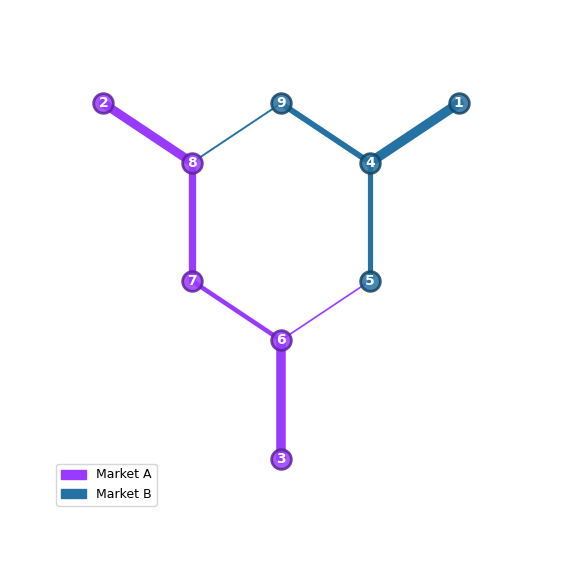

In [6]:
topology_figure()
plt.show()

Slide 4 draws the case as configured: every unit at nameplate, each load, and each line's rating, with line 6-7 at 40 MW in red. Nothing in it is a clearing.

The figure draws the loads every clearing on the deck serves, 173 MW at bus 9 and 90 MW at buses 7 and 5.

fleet: gen_1 bus 3 $20/MWh x 170 MW, gen_0 bus 2 $35/MWh x 300 MW, gen_slack_0 bus 1 $50/MWh x 300 MW

loads: bus 7 90 MW, bus 9 173 MW, bus 5 90 MW

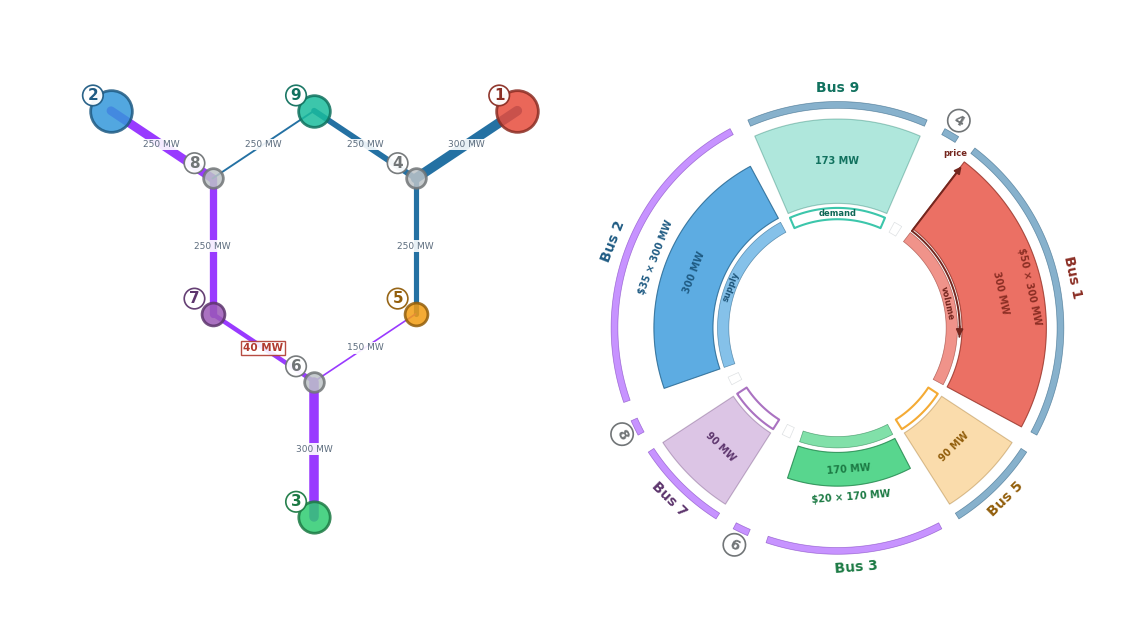

In [7]:
print("fleet: " + ", ".join(
    f"{g} bus {s['bus']} ${s['cost']:.0f}/MWh x {s['p_nom']:.0f} MW"
    for g, s in sorted(FLEET.items(), key=lambda kv: kv[1]["cost"])))
print("loads: " + ", ".join(f"bus {b} {v:.0f} MW" for b, v in LOADS.items()))
configuration_figure()
plt.show()

## Example 1: each market prices every node (slides 5 to 11)

In slide 5, each market clears on its own, with no imports or exports, and prices all nine buses from its own bids, offers and demand. Market A activates line 6-7 at 40 MW. Market B's single unit at bus 1 serves the loads at buses 9 and 5.

In [8]:
ex1 = {mkt: clear(mkt) for mkt in MKT_DEFS}
for mkt, (_, res) in ex1.items():
    duals = {m: round(v, 4) for m, v in res.line_dual.items() if abs(v) > 1e-6}
    dispatch = {g: round(v, 2) for g, v in res.dispatch.items()}
    print(f"{mkt}: production cost ${res.total_cost:,.2f}/h, dispatch {dispatch} MW, "
          f"binding duals {duals}")
prices_1 = pd.DataFrame(
    {f"{mkt} ($/MWh)": [float(res.lmp[b]) for b in PT.buses] for mkt, (_, res) in ex1.items()},
    index=[f"bus {b}" for b in PT.buses]).round(4)
prices_1["footprint"] = [FP.fp_of(b) for b in PT.buses]
display(prices_1)

Market A: production cost $2,537.24/h, dispatch {'gen_0': 49.15, 'gen_1': 40.85} MW, binding duals {'line_4': -20.1024}

Market B: production cost $13,150.00/h, dispatch {'gen_slack_0': 263.0} MW, binding duals {}

,Market A ($/MWh),Market B ($/MWh),footprint
bus 1,27.7362,50.0,Market B
bus 2,35.0000,50.0,Market A
bus 3,20.0000,50.0,Market A
bus 4,27.7362,50.0,Market B
bus 5,25.0197,50.0,Market B
bus 6,20.0000,50.0,Market A
bus 7,37.1260,50.0,Market A
bus 8,35.0000,50.0,Market A
bus 9,30.2461,50.0,Market B


Slide 6 is Market A's clearing. Line 6-7 binds at 40 MW, and Market A's prices separate across the network, from \$20.00/MWh at bus 3 to \$37.13/MWh at bus 7. The buses Market A does not serve are drawn gray and carry a price, by (3).

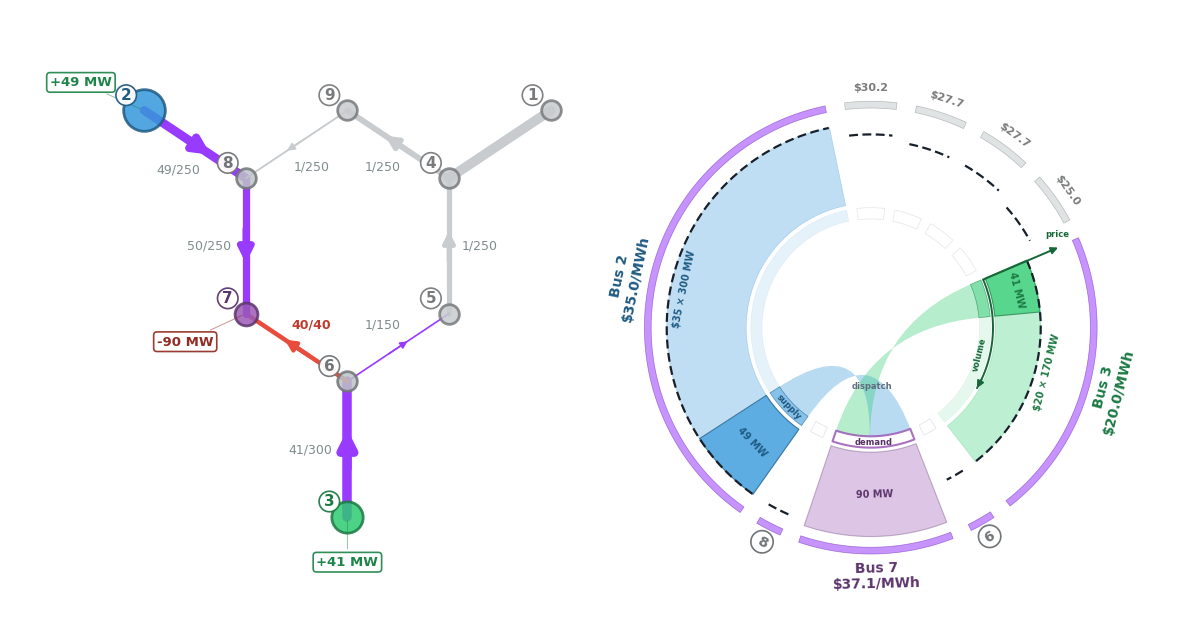

In [9]:
eng_A1, res_A1 = ex1["Market A"]
sv.own_view(NET, PT, FP, "Market A", eng_A1, res_A1)
plt.show()

In [10]:
R_A1 = sum(abs(res_A1.line_dual[m]) * abs(res_A1.flow_own[m])
           for m in ACTIVATED_LINES["Market A"])
mu_A1 = float(res_A1.line_dual["line_4"])
print(f"rent by (4): Market A R^A = {R_A1:.2f} $/h, canonical R = {R_CANON:.2f} $/h, "
      f"residual {R_A1 - R_CANON:+.2e} $/h")
print(f"line 6-7 dual: Market A {mu_A1:.4f} $/MWh, canonical {MU_CANON:.4f} $/MWh, "
      f"residual {mu_A1 - MU_CANON:+.2e} $/MWh")

rent by (4): Market A R^A = 804.09 $/h, canonical R = 804.09 $/h, residual +0.00e+00 $/h

line 6-7 dual: Market A -20.1024 $/MWh, canonical -20.1024 $/MWh, residual +0.00e+00 $/MWh

Slides 7 and 9 read two of Market A's prices as the cost of its redispatch, by (5) and (6). At bus 7, inside Market A, one more MW of load raises the bus 2 unit and lowers the bus 3 unit. At bus 1, outside Market A, one more MW of generation lowers both. Slide 8 is the figure of slide 6 with arrows at bus 1 and its \$27.7 label.

In [11]:
walks_A = {}
for where, bus in WALK_A.items():
    direction = WALK_DIRECTION[bus]
    walk, binding = sv.price_walk(PT, eng_A1, res_A1, bus, direction=direction)
    walks_A[bus] = walk
    print(sv.walk_text(walk, bus, "Market A", float(res_A1.lmp[bus]),
                       inside=(where == "inside"), direction=direction, binding=binding))

Market A -- bus 7, inside its footprint: the cost of one more MW of load

  gen_0 at bus 2: +1.1417 MW  x  $35.00/MWh           =   $    39.96/h
  gen_1 at bus 3: -0.1417 MW  x  $20.00/MWh           =  -$     2.83/h
  ------------------------------------------------------------------
  change in production cost                           =   $    37.13/h
  Market A's price at bus 7                           =   $    37.13/MWh   (binding: line_4)

Market A -- bus 1, outside its footprint: the value of one more MW of generation

  gen_0 at bus 2: -0.5157 MW  x  $35.00/MWh           =  -$    18.05/h
  gen_1 at bus 3: -0.4843 MW  x  $20.00/MWh           =  -$     9.69/h
  ------------------------------------------------------------------
  change in production cost                           =  -$    27.74/h
  Market A's price at bus 1                           =   $    27.74/MWh   (binding: line_4)

Slide 10 is Market B's clearing. No line Market B activates binds, and its single unit at bus 1 sets \$50.00/MWh at every bus. Market B's own flow on line 6-7 is 9.4 MW. Market B does not activate that line, and Market A enforces only its own 40.0 MW, so neither market prices the 49.4 MW the two clearings place on line 6-7 together, against its 40 MW rating.

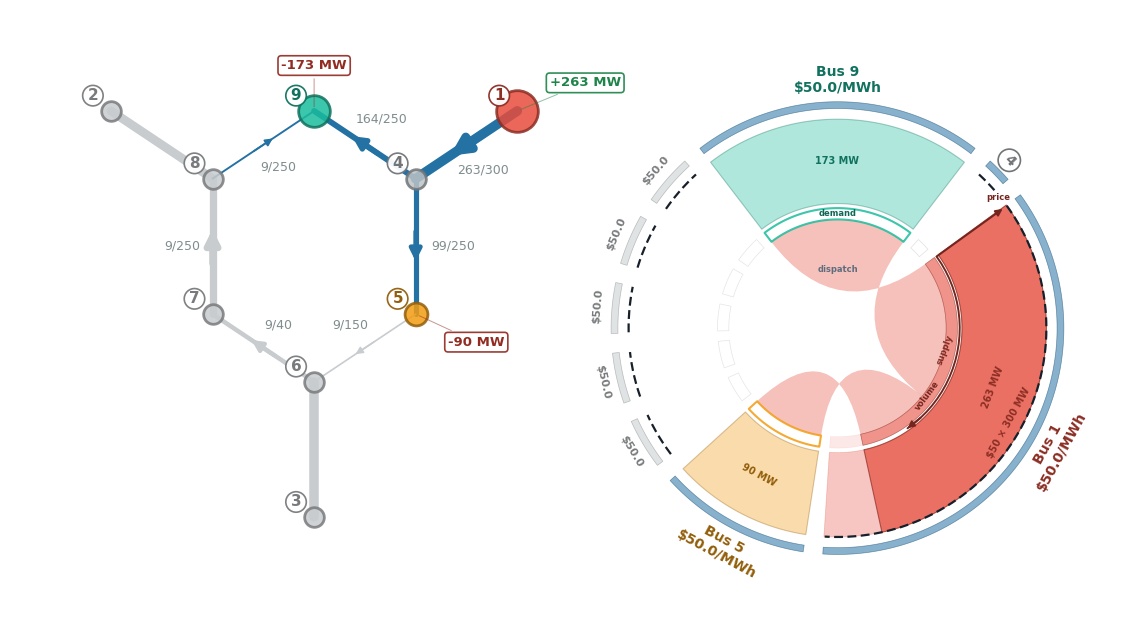

In [12]:
eng_B1, res_B1 = ex1["Market B"]
sv.own_view(NET, PT, FP, "Market B", eng_B1, res_B1)
plt.show()

In [13]:
F_SUM_1 = res_A1.flow_own["line_4"] + res_B1.flow_own["line_4"]  # MW, line 6-7
print(f"line 6-7: Market A {res_A1.flow_own['line_4']:.1f} MW + Market B "
      f"{res_B1.flow_own['line_4']:.1f} MW = {F_SUM_1:.1f} MW, rated {LINE4_RATING:.0f} MW")

line 6-7: Market A 40.0 MW + Market B 9.4 MW = 49.4 MW, rated 40 MW

Slide 11 reads Market B's price at bus 7 as the cost of one more MW of load there. Bus 7 is outside Market B's footprint. The bus 1 unit rises by 1 MW at \$50/MWh.

In [14]:
walks_B = {}
for where, bus in WALK_B.items():
    direction = WALK_DIRECTION[bus]
    walk, binding = sv.price_walk(PT, eng_B1, res_B1, bus, direction=direction)
    walks_B[bus] = walk
    print(sv.walk_text(walk, bus, "Market B", float(res_B1.lmp[bus]),
                       inside=(where == "inside"), direction=direction, binding=binding))

Market B -- bus 7, outside its footprint: the cost of one more MW of load

  gen_slack_0 at bus 1: +1.0000 MW  x  $50.00/MWh     =   $    50.00/h
  ------------------------------------------------------------------
  change in production cost                           =   $    50.00/h
  Market B's price at bus 7                           =   $    50.00/MWh

## Example 2: a balanced self-schedule (slides 12 to 18)

In slide 12, each market accepts a self-scheduled transfer between the market areas as an input to its optimization. The schedule is 25 MW from bus 1, a Market B unit bus, to bus 7, a Market A load bus. By (7), Market A carries +25 MW at bus 1, and Market B carries −25 MW at bus 7. In this example's figures the gray blocks are the schedule's two legs, drawn at each market's own price for the node.

In [15]:
legs_2 = tx_legs({"source": SOURCE_BUS, "sink": SINK_BUS})
src_mkt = next(m for m, leg in legs_2.items() if leg["role"] == "sells")
headroom = (sum(s["p_nom"] for s in FLEET.values() if str(s["bus"]) in MKT_DEFS[src_mkt])
            - sum(v for b, v in LOADS.items() if b in MKT_DEFS[src_mkt]))
print(f"{src_mkt} headroom {headroom:.0f} MW; load at bus {SINK_BUS} {LOADS[SINK_BUS]:.0f} MW; "
      f"schedule {S_SCHED:.0f} MW")
assert S_SCHED <= headroom and S_SCHED <= LOADS[SINK_BUS], "the schedule is not deliverable"

st2 = settle_schedule(SOURCE_BUS, SINK_BUS, S_SCHED)
for mkt in MKT_DEFS:
    r0, r2 = st2[mkt]["res0"], st2[mkt]["res"]
    dispatch = {g: round(v, 2) for g, v in r2.dispatch.items()}
    print(f"{mkt}: production cost {r0.total_cost:,.2f} -> {r2.total_cost:,.2f} $/h "
          f"({r2.total_cost - r0.total_cost:+,.2f}), dispatch {dispatch} MW")

Market B headroom 37 MW; load at bus 7 90 MW; schedule 25 MW

Market A: production cost 2,537.24 -> 1,843.84 $/h (-693.41), dispatch {'gen_0': 36.26, 'gen_1': 28.74} MW

Market B: production cost 13,150.00 -> 14,400.00 $/h (+1,250.00), dispatch {'gen_slack_0': 288.0} MW

Slide 13 is Market A's input before it clears. It carries the schedule as one balanced pair, +25 MW at bus 1 and −25 MW at bus 7, with the flow $S\,(SF_{1,m}-SF_{7,m})$ the pair places on each line by (2). On the ring, Market A's own leg is 25 MW of the 90 MW load at bus 7.

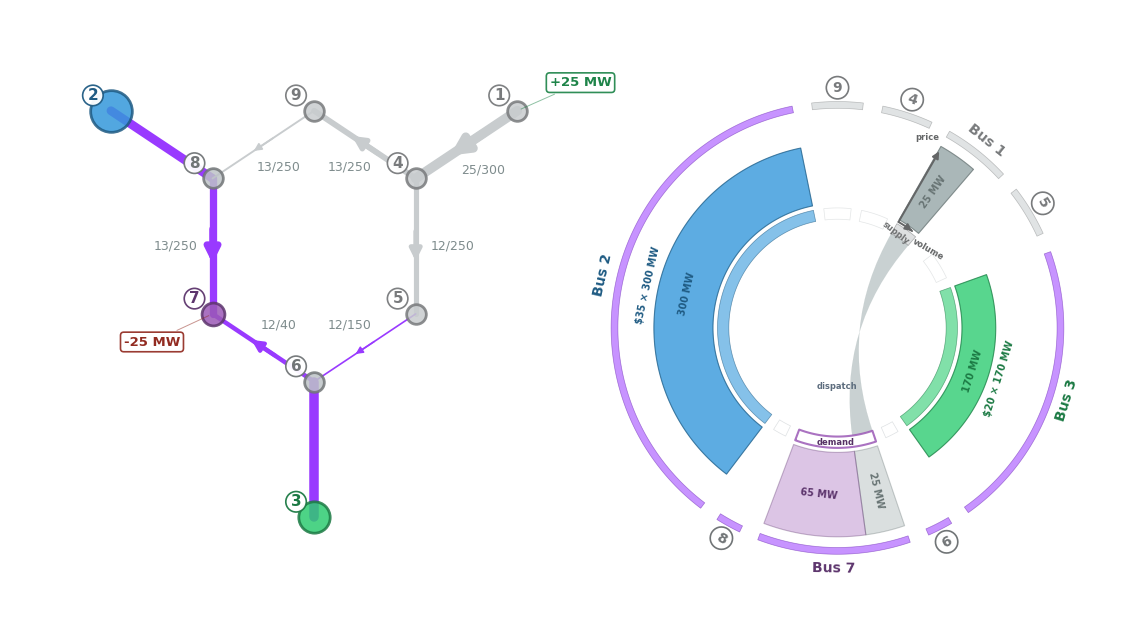

In [16]:
_ = sv.input_view(NET, PT, FP, "Market A", engine("Market A"), SOURCE_BUS, SINK_BUS, S_SCHED)
plt.show()

Slide 14 is Market A's clearing with the schedule. Market A backs its two units down by 25 MW in all, from 49 and 41 MW to 36 and 29 MW. Line 6-7 still binds and both units stay marginal, so every Market A price is unchanged, and Market A pays for the injection at its bus 1 price, \$27.74/MWh.

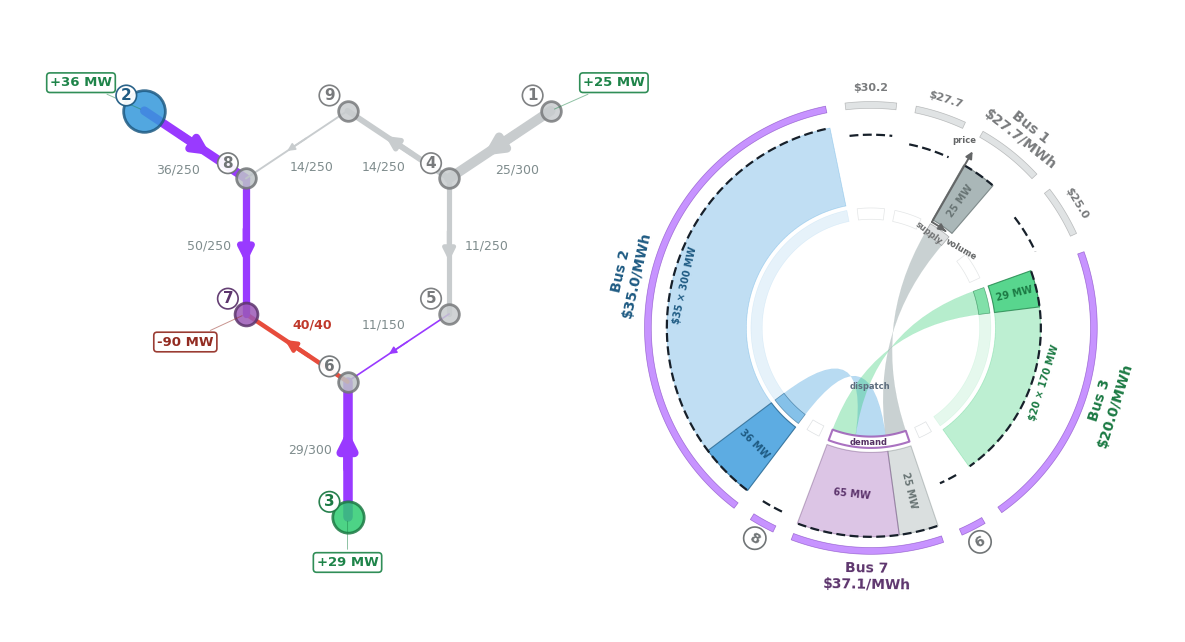

In [17]:
sup_dem, segs = schedule_bars(st2, "Market A")
sv.own_view(NET, PT, FP, "Market A", st2["Market A"]["eng"], st2["Market A"]["res"],
            sup_dem=sup_dem, demand_segments=segs)
plt.show()

Slide 15 is Market B's input, with the same balanced pair and the same flows. On the ring, Market B's own leg is 25 MW of the bus 1 unit's 300 MW, and the withdrawal at bus 7 is a gray demand block.

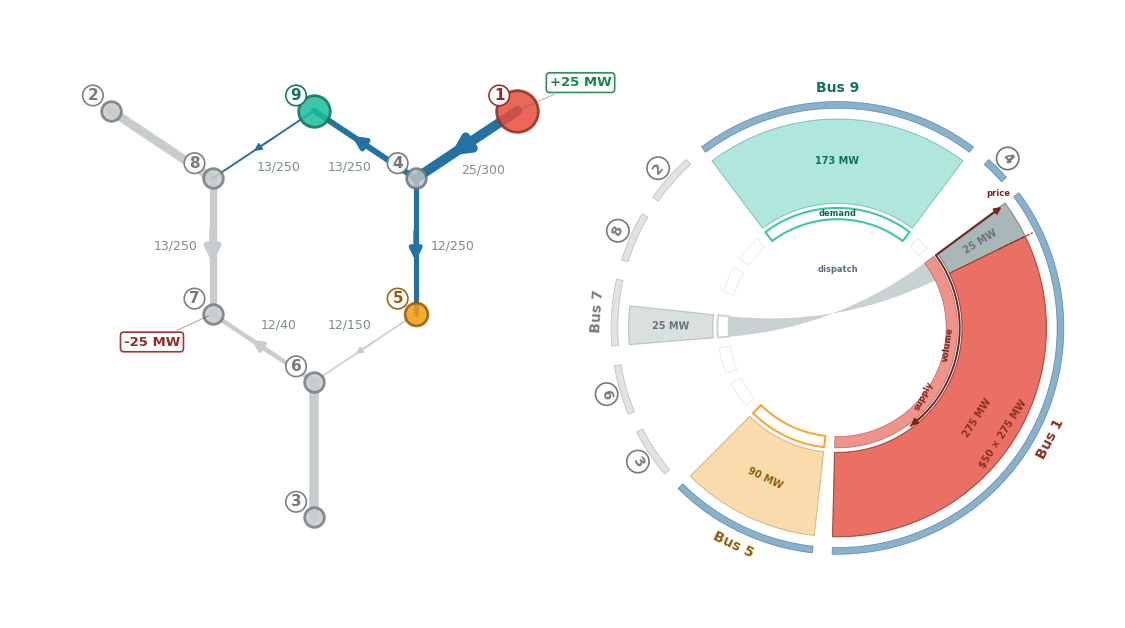

In [18]:
_ = sv.input_view(NET, PT, FP, "Market B", engine("Market B"), SOURCE_BUS, SINK_BUS, S_SCHED)
plt.show()

Slide 16 is Market B's clearing with the schedule. Its bus 1 unit rises from 263 MW to 288 MW at \$50/MWh, and Market B charges for the withdrawal at its bus 7 price, \$50.00/MWh.

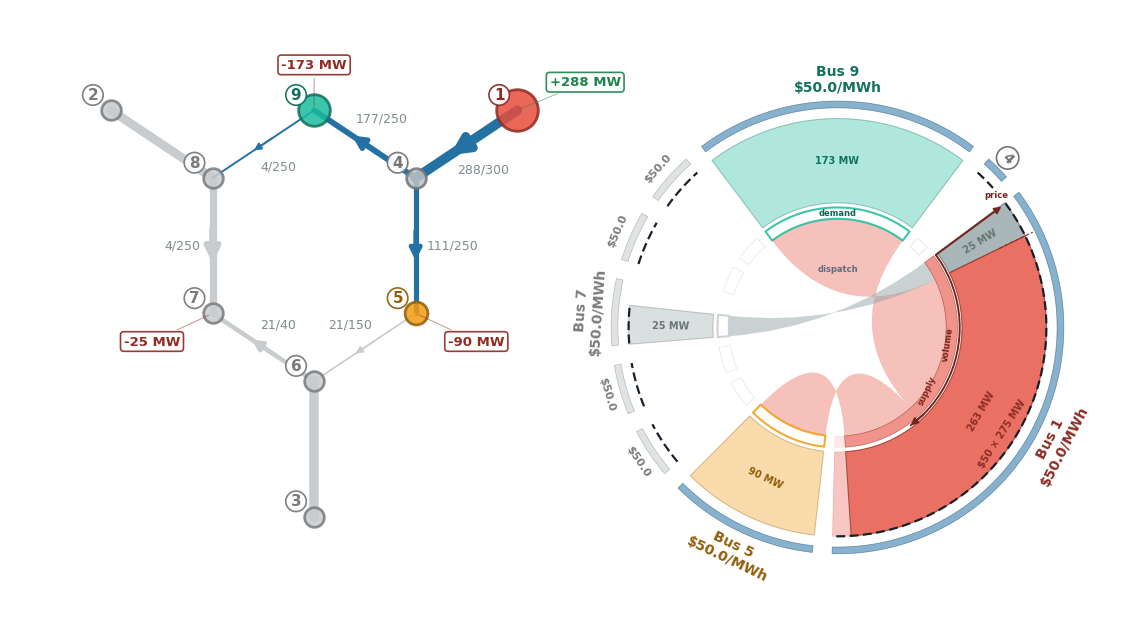

In [19]:
sup_dem, segs = schedule_bars(st2, "Market B")
sv.own_view(NET, PT, FP, "Market B", st2["Market B"]["eng"], st2["Market B"]["res"],
            sup_dem=sup_dem, demand_segments=segs)
plt.show()

Slides 17 and 18 settle the schedule by (8). Market A pays for the injection at bus 1 at its own price there, and Market B charges for the withdrawal at bus 7 at its own price there. Slide 18 repeats the totals.

In [20]:
pay_A, chg_B = st2["Market A"], st2["Market B"]
print(f"+ Market A payment, bus {pay_A['node']} supply: {S_SCHED:.0f} MW x ${pay_A['price']:.4f}/MWh "
      f"= ${pay_A['amount']:,.2f}/h")
print(f"- Market B charge, bus {chg_B['node']} demand: {S_SCHED:.0f} MW x ${chg_B['price']:.4f}/MWh "
      f"= ${-chg_B['amount']:,.2f}/h")
print(f"= transaction total Pi = {usd(st2['pi'])}/h")
dC_2 = {m: st2[m]["res"].total_cost - st2[m]["res0"].total_cost for m in MKT_DEFS}
print("change in production cost: " + ", ".join(f"{m} {v:+,.2f} $/h" for m, v in dC_2.items()))
print(f"Pi = -(dC^A + dC^B): {usd(st2['pi'])}/h against {usd(-sum(dC_2.values()))}/h, "
      f"residual {st2['pi'] + sum(dC_2.values()):+.2e} $/h")

+ Market A payment, bus 1 supply: 25 MW x $27.7362/MWh = $693.41/h

- Market B charge, bus 7 demand: 25 MW x $50.0000/MWh = $1,250.00/h

= transaction total Pi = -$556.59/h

change in production cost: Market A -693.41 $/h, Market B +1,250.00 $/h

Pi = -(dC^A + dC^B): -$556.59/h against -$556.59/h, residual +0.00e+00 $/h

## Example 3: a price-sensitive bid under flat offers (slides 19 to 25)

In slide 19, each market accepts a price-sensitive bid for an import or an export as an input to its optimization. The bid is 30 MW at \$40/MWh from bus 3, a Market A unit bus, to bus 5, a Market B load bus. By (7), Market A sells the export as a withdrawal at bus 5, and Market B buys the import as an injection at bus 3. In this example's figures the gray block is the bid. Its envelope is the bid quantity, and its solid fill is the award.

In [21]:
legs_3 = tx_legs(TX_BID)
for mkt in MKT_DEFS:
    leg = legs_3[mkt]
    p0 = price_at(mkt, leg, 0.0)[0]
    pq = price_at(mkt, leg, QTY_3)[0]
    print(f"{mkt} {leg['role']} at bus {leg['node']}: price ${p0:.4f}/MWh at 0 MW, "
          f"${pq:.4f}/MWh at {QTY_3:.0f} MW")
st3 = settle_bid(TX_BID, BID_3, QTY_3)
for mkt in MKT_DEFS:
    print(f"{mkt} awards {st3[mkt]['award']:.2f} MW at bus {st3[mkt]['node']}, "
          f"its price there ${st3[mkt]['price']:.4f}/MWh")

Market A sells at bus 5: price $25.0197/MWh at 0 MW, $25.0197/MWh at 30 MW

Market B buys at bus 3: price $50.0000/MWh at 0 MW, $50.0000/MWh at 30 MW

Market A awards 30.00 MW at bus 5, its price there $25.0197/MWh

Market B awards 30.00 MW at bus 3, its price there $50.0000/MWh

Slide 20 is Market A's book as configured, with the 30 MW export at bus 5 and no flows, because the bid places none before the clearing.

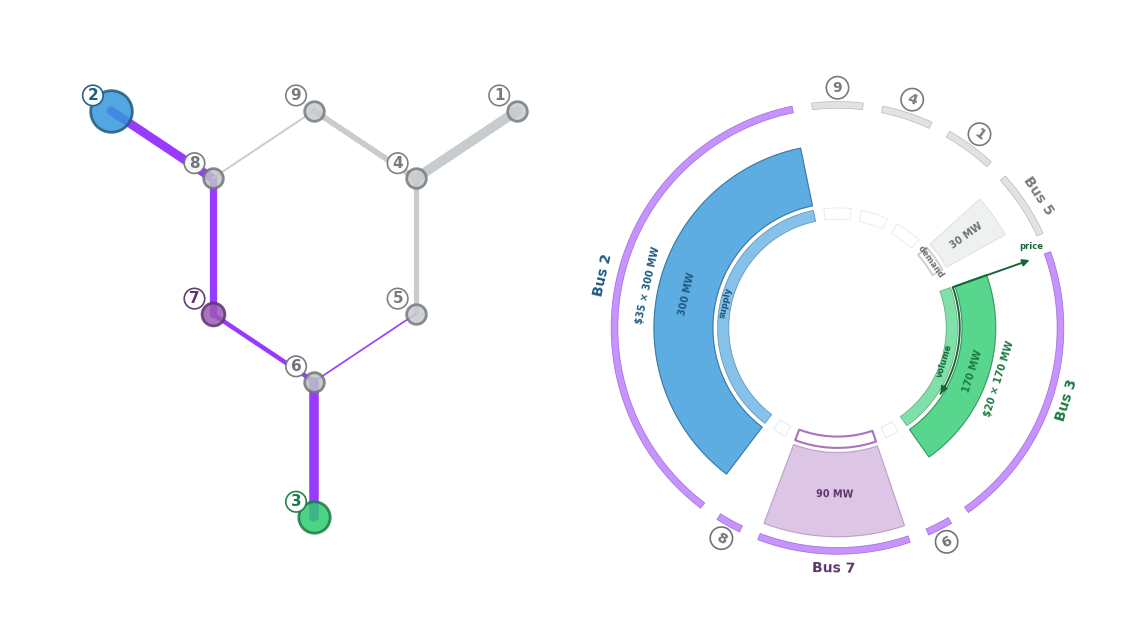

In [22]:
leg = legs_3["Market A"]
_ = sv.bid_view(NET, PT, FP, "Market A", engine("Market A"), leg["node"], QTY_3, BID_3, leg["kind"])
plt.show()

Slide 21 is Market A's award. Market A's price at bus 5 is \$25.02/MWh at every volume up to 30 MW, below the \$40 bid, so it awards the whole 30 MW, and its bus 2 and bus 3 units rise to 59 and 61 MW to serve it.

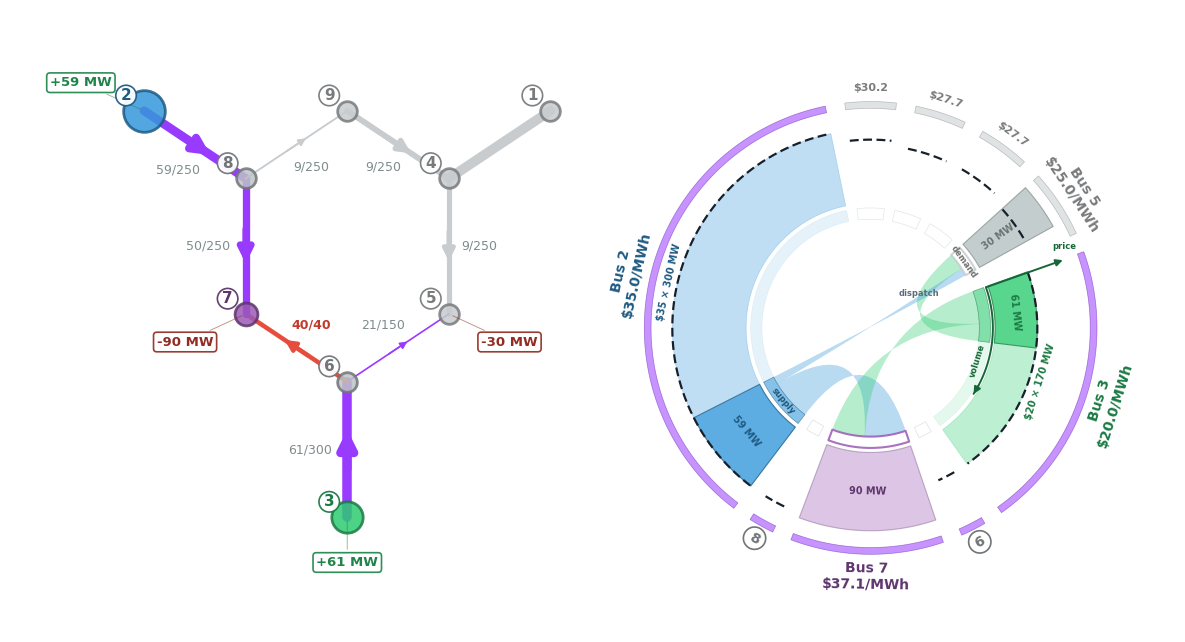

In [23]:
a3 = st3["Market A"]
sup_dem, segs = figs.bid_bars(a3["eng"], a3["res"], a3["node"], a3["kind"], QTY_3, a3["award"], BID_3)
sv.own_view(NET, PT, FP, "Market A", a3["eng"], a3["res"], sup_dem=sup_dem, demand_segments=segs)
plt.show()

Slide 22 is Market B's book as configured, with the 30 MW import offered at bus 3 at \$40/MWh.

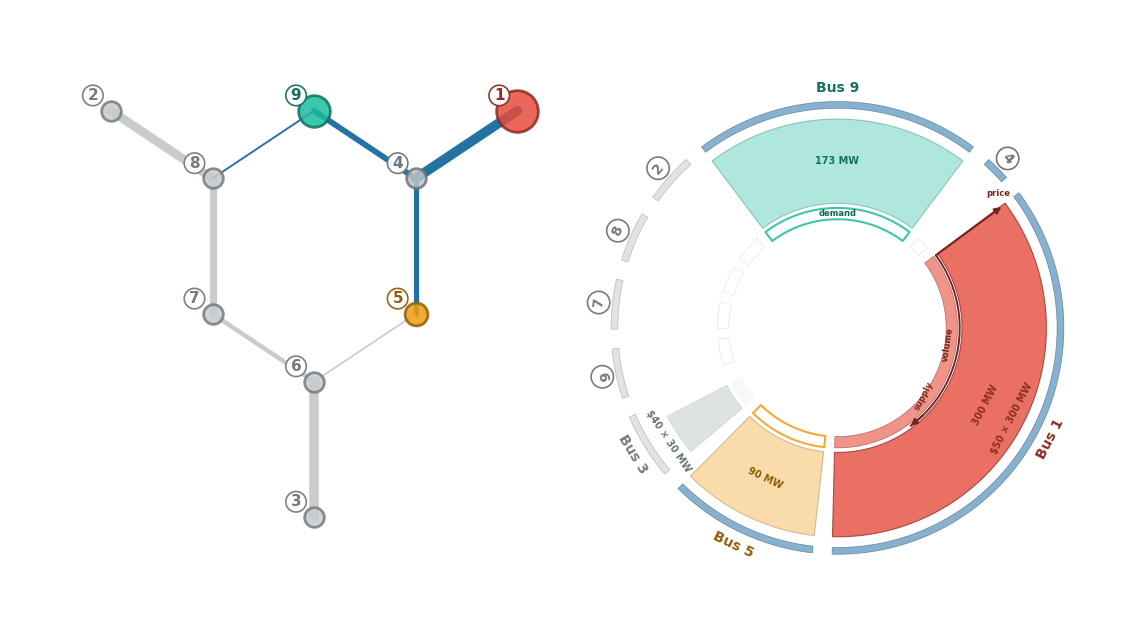

In [24]:
leg = legs_3["Market B"]
_ = sv.bid_view(NET, PT, FP, "Market B", engine("Market B"), leg["node"], QTY_3, BID_3, leg["kind"])
plt.show()

Slide 23 is Market B's award. Its price at bus 3 is \$50.00/MWh, above the \$40 bid, so it takes the whole 30 MW, and its bus 1 unit backs down from 263 MW to 233 MW.

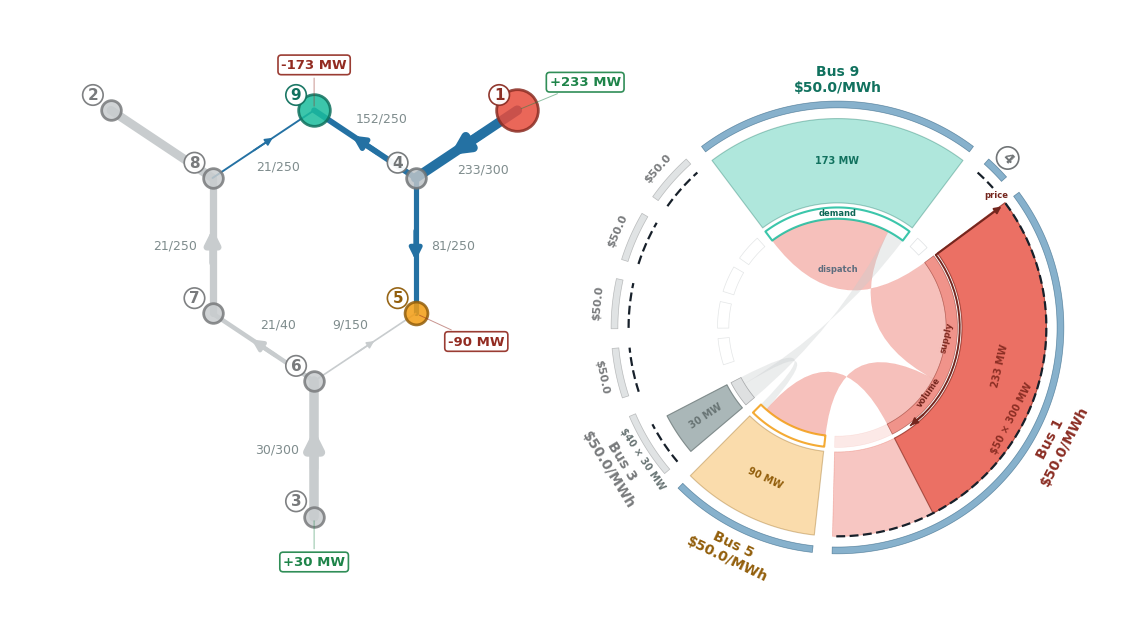

In [25]:
b3 = st3["Market B"]
sup_dem, segs = figs.bid_bars(b3["eng"], b3["res"], b3["node"], b3["kind"], QTY_3, b3["award"], BID_3)
sv.own_view(NET, PT, FP, "Market B", b3["eng"], b3["res"], sup_dem=sup_dem, demand_segments=segs)
plt.show()

Slides 24 and 25 settle the bid by (10). Market B pays for the import at bus 3 at its own price, and Market A charges for the export at bus 5 at its own price. Slide 25 repeats the totals.

In [26]:
print(f"+ Market B payment, bus {b3['node']} gen: {b3['award']:.0f} MW x ${b3['price']:.4f}/MWh "
      f"= ${b3['amount']:,.2f}/h")
print(f"- Market A charge, bus {a3['node']} demand: {a3['award']:.0f} MW x ${a3['price']:.4f}/MWh "
      f"= ${-a3['amount']:,.2f}/h")
print(f"= transaction total Pi = {usd(st3['pi'])}/h")

+ Market B payment, bus 3 gen: 30 MW x $50.0000/MWh = $1,500.00/h

- Market A charge, bus 5 demand: 30 MW x $25.0197/MWh = $750.59/h

= transaction total Pi = $749.41/h

## Example 4: the same bid under rising offer curves (slides 26 to 33)

Slide 26 repeats the setting of slide 19, and slides 27 to 30 draw each unit as a sloped wedge. The offers are the rising curves of (11). The block below prints the coefficients. No slide states them. They reproduce every price and dispatch that slides 28 and 30 print. The bid is 120 MW at \$40/MWh on the same transaction, bus 3 to bus 5.

In [27]:
for g, (a, b) in CURVES_TX.items():
    print(f"{g} at bus {FLEET[g]['bus']}: MC = {a:.1f} + {b:.3f} g $/MWh")
st4 = settle_bid(TX_BID, BID_4, QTY_4, curves=CURVES_TX)
for mkt in MKT_DEFS:
    print(f"{mkt} awards {st4[mkt]['award']:.2f} MW at bus {st4[mkt]['node']}, "
          f"its price there ${st4[mkt]['price']:.2f}/MWh")
print(f"tagged {st4['tagged']:.2f} MW; open position {st4['open']:+.2f} MW in {st4['rt']['market']}")
for mkt in MKT_DEFS:  # (9): a partial award is the marginal bid, priced at the bid
    s4 = st4[mkt]
    if 1e-6 < s4["award"] < QTY_4 - 1e-6:  # MW, the partial-award test of settle_bid
        lam = float(s4["res"].lmp[s4["node"]])
        print(f"{mkt} clearing at its award: price at bus {s4['node']} ${lam:.4f}/MWh, "
              f"bid ${BID_4:.2f}/MWh, residual {lam - BID_4:+.2e} $/MWh")

gen_slack_0 at bus 1: MC = 24.0 + 0.100 g $/MWh

gen_0 at bus 2: MC = 28.0 + 0.270 g $/MWh

gen_1 at bus 3: MC = 15.0 + 0.335 g $/MWh

Market A awards 39.79 MW at bus 5, its price there $40.00/MWh

Market B awards 103.00 MW at bus 3, its price there $40.00/MWh

tagged 39.79 MW; open position +63.21 MW in Market B

Market A clearing at its award: price at bus 5 $40.0000/MWh, bid $40.00/MWh, residual +1.00e-09 $/MWh

Market B clearing at its award: price at bus 3 $40.0000/MWh, bid $40.00/MWh, residual -1.00e-09 $/MWh

Slide 27 is Market A's book as configured, with the 120 MW export at bus 5.

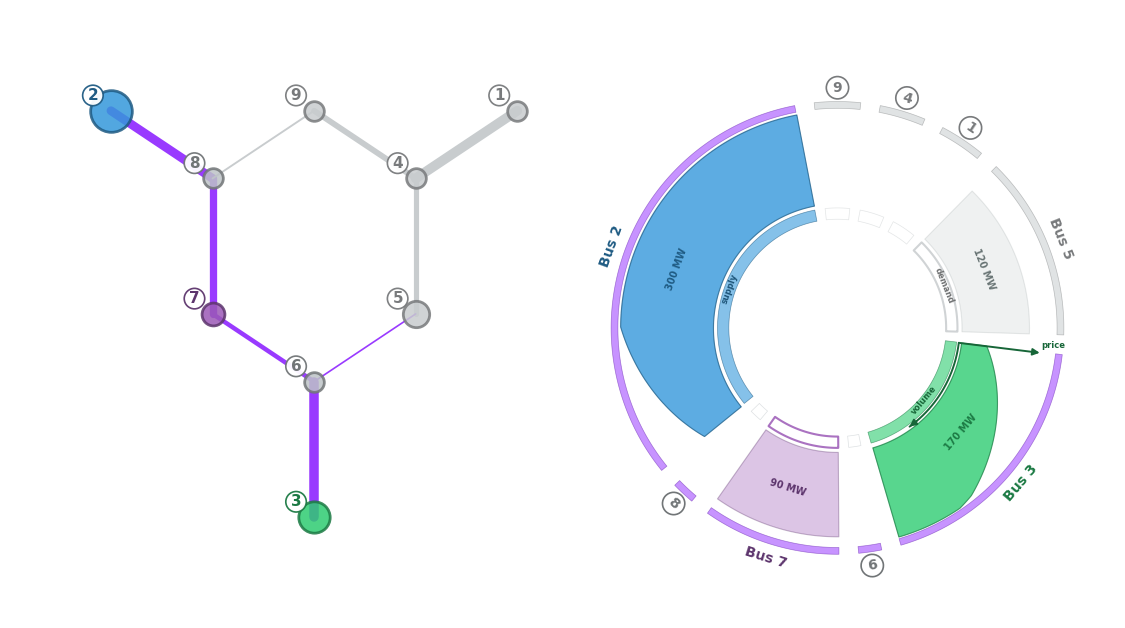

In [28]:
leg = st4["Market A"]
_ = sv.bid_view(NET, PT, FP, "Market A", engine("Market A"), leg["node"], QTY_4, BID_4,
                leg["kind"], curves=CURVES_TX)
plt.show()

Slide 28 is Market A's award. Market A's price at bus 5 rises with the volume it serves and reaches the \$40 bid at 39.79 MW. The bid's remaining 80.21 MW goes unawarded.

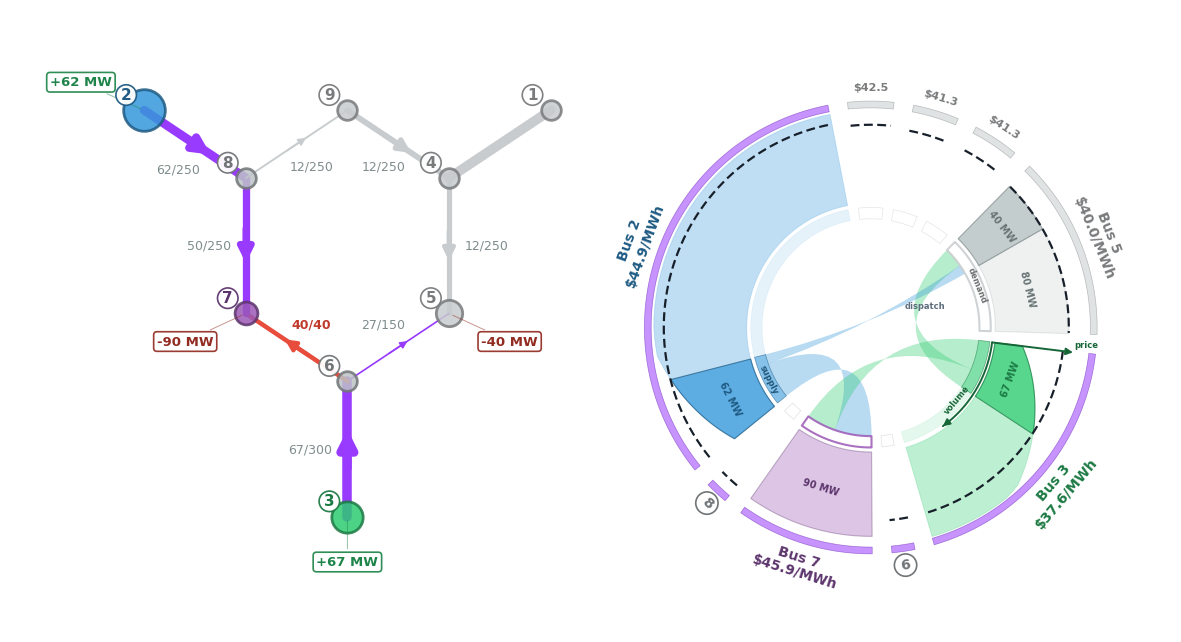

In [29]:
a4 = st4["Market A"]
sup_dem, segs = figs.bid_bars(a4["eng"], a4["res"], a4["node"], a4["kind"], QTY_4, a4["award"], BID_4)
sv.own_view(NET, PT, FP, "Market A", a4["eng"], a4["res"], sup_dem=sup_dem,
            demand_segments=segs, curves=CURVES_TX)
plt.show()

Slide 29 is Market B's book as configured, with the 120 MW import offered at bus 3.

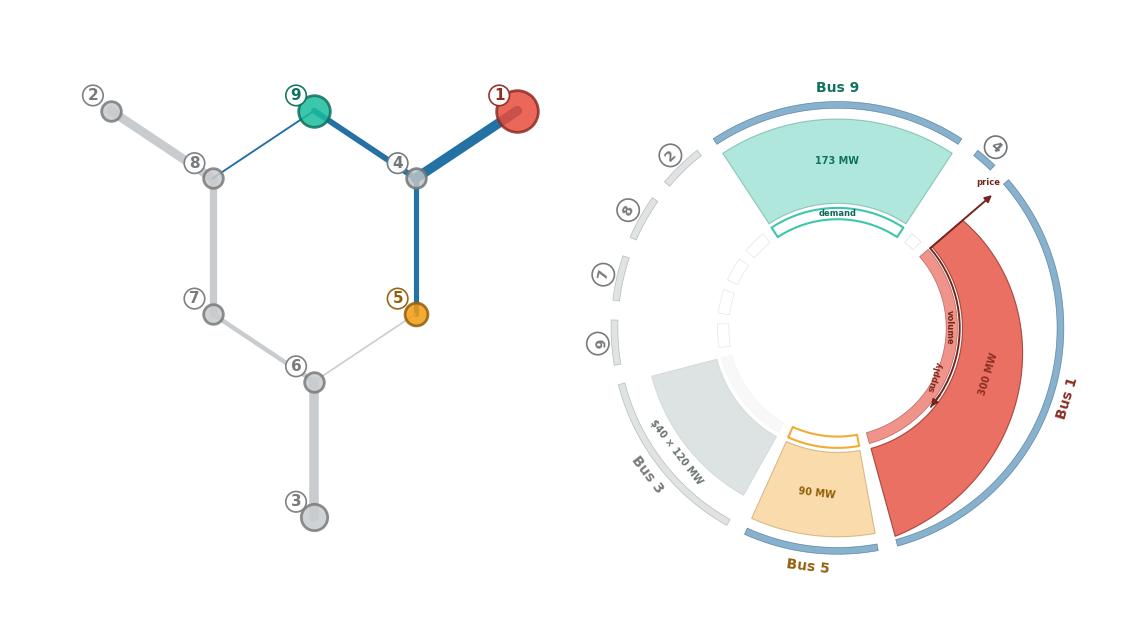

In [30]:
leg = st4["Market B"]
_ = sv.bid_view(NET, PT, FP, "Market B", engine("Market B"), leg["node"], QTY_4, BID_4,
                leg["kind"], curves=CURVES_TX)
plt.show()

Slide 30 is Market B's award. Market B's price at bus 3 falls as it takes more of the import and reaches the \$40 bid at 103 MW, where its bus 1 unit runs at 160 MW.

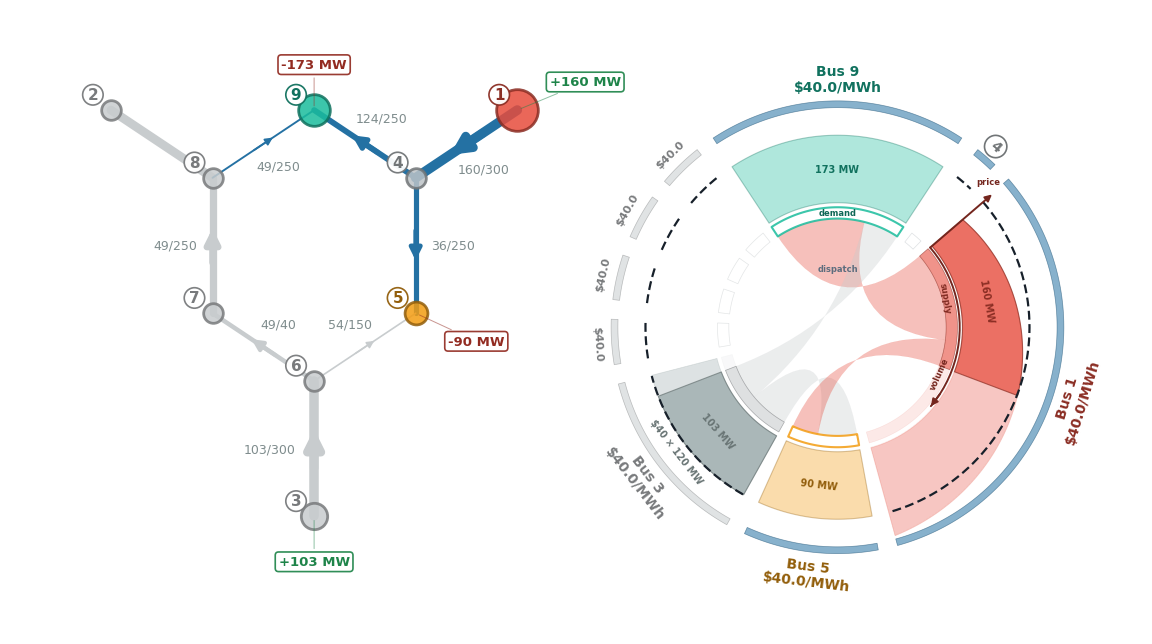

In [31]:
b4 = st4["Market B"]
sup_dem, segs = figs.bid_bars(b4["eng"], b4["res"], b4["node"], b4["kind"], QTY_4, b4["award"], BID_4)
sv.own_view(NET, PT, FP, "Market B", b4["eng"], b4["res"], sup_dem=sup_dem,
            demand_segments=segs, curves=CURVES_TX)
plt.show()

Slide 31 is the scheduler's open position. Market B awarded 103 MW and Market A 39.79 MW, so only 39.79 MW can be tagged, and the scheduler is 63.21 MW short in Market B. By (12), Market B re-clears in real time with 39.79 MW delivered at bus 3. Its bus 1 unit rises by the 63.21 MW, and its price at every bus rises to \$46.32/MWh. On the ring the bid block at bus 3 is solid for the delivered volume and faint for the shortfall, and the hatched block at bus 1 is the unit's increase.

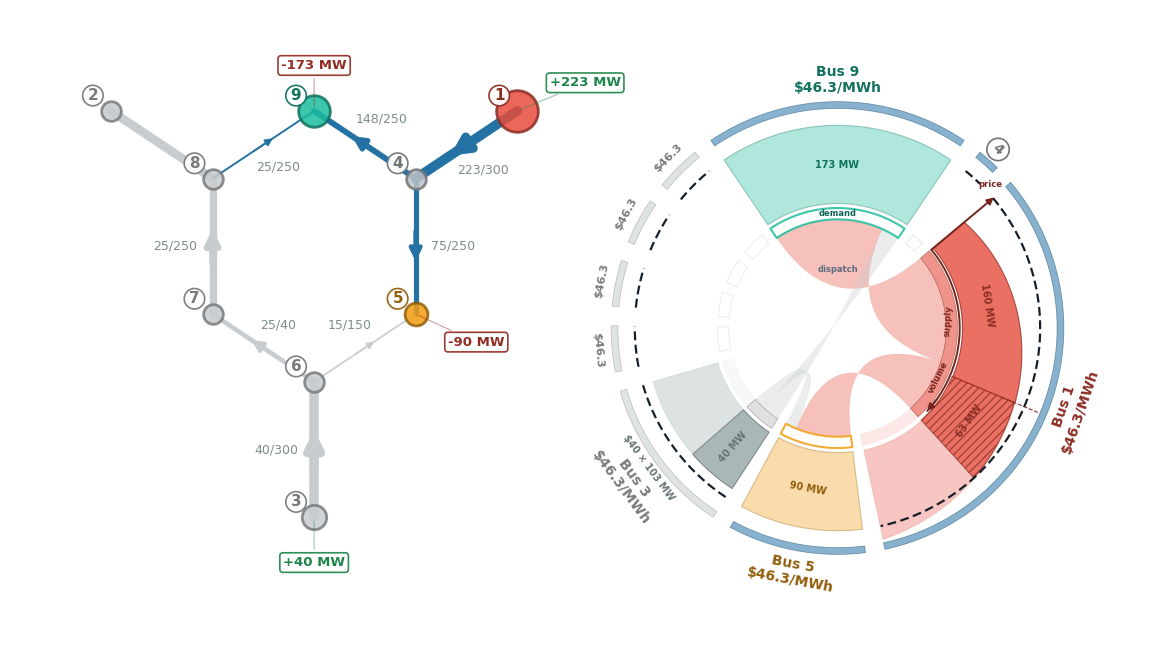

+ Market B payment, bus 3 gen: 103.00 MW x $40.00/MWh = $4,120.00/h

- Market A charge, bus 5 demand: 39.79 MW x $40.00/MWh = -$1,591.45/h

open position: 63.21 MW short in Market B

- Market B real-time buy-back at bus 3: 63.21 MW x $46.32/MWh = -$2,928.15/h

Market B real time: production cost $7,848.35/h, gen_slack_0 at bus 1 160.00 -> 223.21 MW

In [32]:
rt = st4["rt"]
leg = st4[rt["market"]]
shortfall = abs(st4["open"])
rise = {g: rt["res"].dispatch[g] - leg["res"].dispatch[g] for g in rt["res"].dispatch}
unit = max(rise, key=rise.get)  # the unit that replaces the volume
sup_dem, _ = figs.bid_bars(rt["eng"], rt["res"], leg["node"], leg["kind"], leg["award"],
                           st4["tagged"], BID_4)
sup_dem, _ = figs.redispatch_bars(rt["eng"], rt["res"], str(FLEET[unit]["bus"]), shortfall,
                                  sup_dem=sup_dem, curves=CURVES_TX)
sv.own_view(NET, PT, FP, rt["market"], rt["eng"], rt["res"], sup_dem=sup_dem, curves=CURVES_TX)
plt.show()
print(f"+ Market B payment, bus {b4['node']} gen: {b4['award']:.2f} MW x ${b4['price']:.2f}/MWh "
      f"= {usd(b4['amount'])}/h")
print(f"- Market A charge, bus {a4['node']} demand: {a4['award']:.2f} MW x ${a4['price']:.2f}/MWh "
      f"= {usd(a4['amount'])}/h")
print(f"open position: {shortfall:.2f} MW short in {rt['market']}")
print(f"- {rt['market']} real-time buy-back at bus {leg['node']}: {shortfall:.2f} MW x "
      f"${rt['price']:.2f}/MWh = {usd(st4['rt_amount'])}/h")
print(f"{rt['market']} real time: production cost ${rt['res'].total_cost:,.2f}/h, "
      f"{unit} at bus {FLEET[unit]['bus']} {leg['res'].dispatch[unit]:.2f} -> "
      f"{rt['res'].dispatch[unit]:.2f} MW")

Slide 32 tabulates the scheduler's transactions in Example 4. The position column below carries the sign of its amount, negative for a purchase and positive for a sale. The Net row sums the position and amount columns. The positions sum to zero, and the amounts sum to −\$399.60/h. Slide 33 repeats the 63 MW open position.

In [33]:
tx_4 = transactions_table(st4)
display(tx_4.style.format(precision=2, na_rep=""))

Slide 34 closes the deck with its key points and carries no number.

## Sandbox

The sandbox reruns this notebook's chain on the values of the `# -- EDIT --` cell: Example 1's prices at the walked buses, Example 2's settlement, and the awards and settlements of Examples 3 and 4. It draws no figure. The knobs are the footprints, the monitored and activated lines, the bus 1 unit's capacity, the ratings of lines 1-4 and 6-7, the loads, the shed price, the walked buses, Example 2's source, sink and schedule, and the transaction, bids, quantities and offer curves of Examples 3 and 4. A clearing that sheds load stops the chain with an `AssertionError` that names the market, as a self-schedule above Market B's 37 MW of headroom does. The notebook `101_sandbox.ipynb` clears the 9-bus network on the same footprints and each market's monitored set from one configuration cell, as one market or as two, with the settlement and allocation ledgers. Its defaults are the stock fleet and loads, and its `FLEET`, `LOADS` and `LINE_RATINGS` knobs set this notebook's values.

In [34]:
FLEET, NET, PT, FP = build_case()
display(run_chain())

value
example quantity                                
1       Market A price at bus 7 ($/MWh)    37.13
        Market A price at bus 1 ($/MWh)    27.74
        Market B price at bus 7 ($/MWh)    50.00
2       Market A price at bus 1 ($/MWh)    27.74
        Market B price at bus 7 ($/MWh)    50.00
        scheduler's net Pi ($/h)         -556.59
3       Market B award at bus 3 (MW)       30.00
        Market B price at bus 3 ($/MWh)    50.00
        Market A award at bus 5 (MW)       30.00
        Market A price at bus 5 ($/MWh)    25.02
        open position (MW)                  0.00
        scheduler's net Pi ($/h)          749.41
4       Market B award at bus 3 (MW)      103.00
        Market B price at bus 3 ($/MWh)    40.00
        Market A award at bus 5 (MW)       39.79
        Market A price at bus 5 ($/MWh)    40.00
        open position (MW)                 63.21
        Market B real-time price ($/MWh)   46.32
        scheduler's net Pi ($/h)         -399.60